# Stage 05.2 verification: annual-mean (non-seasonal) 10-member-ensemble-mean PGW perturbation

Checks whatever `04_apply_perturbation.py --annual` has actually produced under
`config.PERTURBED_IM_DIR_ANNUAL` against the real ERA5 WPS intermediate files it
perturbed. Test dates are **auto-discovered** from the perturbed-file directory
(not hardcoded), same style as `05.1_verify_perturbation_monthSpecific.ipynb`, so
this notebook stays correct as more years/months get run.

Same three checks as `05.1`, plus two specific to annual-mean mode (a single
non-seasonal delta is a different claim than a month-varying one, and deserves
its own evidence):

1. **Structural integrity** -- every field/record *not* in the perturbation set is
   byte-identical between original and perturbed files; only the expected
   fields/records changed. `perturb_field`'s logic is completely unchanged between
   month-specific and `--annual` mode -- only *which* delta values get looked up
   differs -- so this exercises the same shared code path as `05.1`.
2. **Quantitative correctness** -- the applied delta (`perturbed - original`)
   matches the stage-03 **annual-mean** delta file (`DELTA_DIR/ann.nc`) exactly
   (modulo the documented RH clip and SST floor), regardless of which calendar
   month a test file's own date falls in.
3. **Physical plausibility** -- maps and vertical profiles of the applied delta
   reproduce the expected PGW/climate-change signature, driven by the 10-member
   LENS2 ensemble-mean warming signal.
4. **Annual != month-specific** -- confirms `ann.nc` is not accidentally identical
   to any single month's delta (checked against June's `06.nc`, since that's what
   the main-stream `ERA5:*` test files happen to be), which would silently defeat
   the point of `--annual`.
5. **Cross-month consistency** -- the whole premise of `--annual` is that *every*
   calendar month gets the *same* delta. The auto-discovered SST-update stream
   (`SST_1984/ERA5_SST:*` -> `SST_UPDATE:*`) spans several different calendar
   months in one run (not just June), giving a direct, on-disk check that files
   from different months all received the same annual delta.

Also verifies the separate periodic SST-update stream (`ERA5_SST:*` ->
`SST_UPDATE:*`), which uses a different file layout/land-mask than the main
archive -- same as `05.1`.

Run with the `Python (casper_2023)` kernel (same env/config as the pipeline itself).

In [1]:
import sys
sys.path.insert(0, "/glade/u/home/mingge/MPAS/MPAS_LENS2_PGW_ENS10")  # so `import config`/`lib` below resolve

import importlib.util
import glob
from pathlib import Path

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

import config              # this project's paths/constants (grid, periods, field lists, ...)
import lib.wps_intermediate as wps  # reader/writer for the binary WPS intermediate-file format

# Load 04_apply_perturbation.py as a module via importlib (its filename starts with a
# digit, so `import 04_apply_perturbation` isn't valid syntax) -- reusing it directly
# means this notebook can't silently drift from what stage 04 actually does:
# SST_FLOOR_K, SST_FILL_THRESHOLD, load_ocean_mask(), load_annual_delta(), and the
# regexes that recognize ERA5:*/ERA5_SST:* filenames all come from the one place
# that matters.
_spec = importlib.util.spec_from_file_location(
    "apply_pgw", "/glade/u/home/mingge/MPAS/MPAS_LENS2_PGW_ENS10/04_apply_perturbation.py")
apply_pgw = importlib.util.module_from_spec(_spec)
_spec.loader.exec_module(apply_pgw)

ORIG_DIR = config.ERA5_IM_DIR              # real ERA5 WPS intermediate files (never modified)
PERT_DIR = config.PERTURBED_IM_DIR_ANNUAL  # --annual output, NOT config.PERTURBED_IM_DIR
print("originals:            ", ORIG_DIR)
print("perturbed (annual):   ", PERT_DIR)

originals:             /glade/campaign/mmm/c3we/mingge/wpsv4.5_mpas
perturbed (annual):    /glade/campaign/mmm/c3we/mingge/wpsv4.5_mpas_LENS2PGW_ens10mean_annualmean


## Auto-discover what stage 04's `--annual` run has actually produced

Main `ERA5:*` archive test dates, plus the separate `SST_<year>/ERA5_SST:*` ->
`SST_UPDATE:*` stream -- same auto-discovery as `05.1`, pointed at
`PERTURBED_IM_DIR_ANNUAL` instead.

In [2]:
pert_files = sorted(PERT_DIR.glob(f"{config.ERA5_IM_PREFIX}:*"))
test_dates = [f.name.split(":")[1] for f in pert_files if apply_pgw._IM_NAME_RE.match(f.name)]
print(f"{len(test_dates)} main-stream test files:")
for d in test_dates:
    print(" ", d)

_sst_pattern = str(PERT_DIR / "SST_*" / f"{apply_pgw._SST_UPDATE_PREFIX}:*")
sst_pert_files = sorted(Path(p) for p in glob.glob(_sst_pattern))
sst_months_present = sorted({f.name.split(":")[1][5:7] for f in sst_pert_files})
print(f"\n{len(sst_pert_files)} SST-update test files, spanning calendar months {sst_months_present}")
for f in (sst_pert_files[:3] + (["..."] if len(sst_pert_files) > 6 else []) + sst_pert_files[-3:]):
    print(" ", f)

6 main-stream test files:
  1984-06-01_00
  1984-06-02_00
  1984-06-03_00
  1984-06-04_00
  1984-06-05_00
  1984-06-06_00

184 SST-update test files, spanning calendar months ['06', '07', '08', '09', '10', '11', '12']
  /glade/campaign/mmm/c3we/mingge/wpsv4.5_mpas_LENS2PGW_ens10mean_annualmean/SST_1984/SST_UPDATE:1984-06-01_00
  /glade/campaign/mmm/c3we/mingge/wpsv4.5_mpas_LENS2PGW_ens10mean_annualmean/SST_1984/SST_UPDATE:1984-06-02_00
  /glade/campaign/mmm/c3we/mingge/wpsv4.5_mpas_LENS2PGW_ens10mean_annualmean/SST_1984/SST_UPDATE:1984-06-03_00
  ...
  /glade/campaign/mmm/c3we/mingge/wpsv4.5_mpas_LENS2PGW_ens10mean_annualmean/SST_1984/SST_UPDATE:1984-11-29_00
  /glade/campaign/mmm/c3we/mingge/wpsv4.5_mpas_LENS2PGW_ens10mean_annualmean/SST_1984/SST_UPDATE:1984-11-30_00
  /glade/campaign/mmm/c3we/mingge/wpsv4.5_mpas_LENS2PGW_ens10mean_annualmean/SST_1984/SST_UPDATE:1984-12-01_00


## 1. Structural integrity

Same check as `05.1`: for every test file, same record count and order, same
field/level list. Every record's slab must be **byte-identical** to the original
*unless* it's one of the fields stage 04 is documented to touch (`GHT`, `TT`, `RH`
at pressure levels, `SKINTEMP`, `SST`-over-ocean). This part of stage 04's logic
(`perturb_field`) is completely unchanged between month-specific and `--annual`
mode -- only *which* delta values get looked up differs -- so a regression here
would indicate something broke in the shared code path, not the annual-mean-
specific addition.

In [3]:
PERTURBED_3D = set(config.PERTURB_FIELDS_3D)           # {GHT, TT, RH}
PERTURBED_SFC = set(config.PERTURB_FIELDS_SFC.keys())  # {SST, SKINTEMP}

def key(rec):
    return (rec.field, round(rec.xlvl, 3))

def check_file(date):
    orig = wps.read_file(ORIG_DIR / f"{config.ERA5_IM_PREFIX}:{date}")
    pert = wps.read_file(PERT_DIR / f"{config.ERA5_IM_PREFIX}:{date}")

    assert len(orig) == len(pert), f"{date}: record count changed ({len(orig)} vs {len(pert)})"
    assert [key(r) for r in orig] == [key(r) for r in pert], f"{date}: field/level order changed"

    touched, untouched_changed = [], []
    for ro, rp in zip(orig, pert):
        changed = not np.array_equal(ro.slab, rp.slab)
        is_sfc_sentinel = ro.xlvl == config.ERA5_SURFACE_LEVEL_PA
        expected_perturbable = (
            (ro.field in PERTURBED_3D and not is_sfc_sentinel) or
            (ro.field in PERTURBED_SFC)
        )
        if changed:
            touched.append(key(ro))
            if not expected_perturbable:
                untouched_changed.append(key(ro))

    return dict(date=date, n_records=len(orig), n_touched=len(touched),
                fields_present={r.field for r in orig},
                unexpected_changes=untouched_changed, orig=orig, pert=pert)

results = [check_file(d) for d in test_dates]
for r in results:
    status = "OK" if not r["unexpected_changes"] else "FAIL"
    print(f"{r['date']}: {r['n_touched']:3d}/{r['n_records']} records touched  [{status}]  "
          f"fields={sorted(r['fields_present'])}")
    if r["unexpected_changes"]:
        print("   unexpected changes in:", r["unexpected_changes"])

assert all(not r["unexpected_changes"] for r in results), "a field outside the perturbation set was modified"

touched_counts = {r["date"]: r["n_touched"] for r in results}
print(f"\ntouched-record counts by date: {touched_counts}")
if len(set(touched_counts.values())) > 1:
    print("(not uniform -- expected: ERA5:* only carries an SST record on some days, see section 2)")

1984-06-01_00: 112/204 records touched  [OK]  fields=['GHT', 'LANDSEA', 'PMSL', 'PSFC', 'RH', 'SEAICE', 'SKINTEMP', 'SM000007', 'SM007028', 'SM028100', 'SM100289', 'SNOW', 'SOILHGT', 'ST000007', 'ST007028', 'ST028100', 'ST100289', 'TT', 'UU', 'VV']
1984-06-02_00: 113/242 records touched  [OK]  fields=['GHT', 'LANDSEA', 'PMSL', 'PSFC', 'RH', 'SEAICE', 'SKINTEMP', 'SM000007', 'SM007028', 'SM028100', 'SM100289', 'SNOW', 'SOILHGT', 'SPECHUMD', 'SST', 'ST000007', 'ST007028', 'ST028100', 'ST100289', 'TT', 'UU', 'VV']
1984-06-03_00: 113/242 records touched  [OK]  fields=['GHT', 'LANDSEA', 'PMSL', 'PSFC', 'RH', 'SEAICE', 'SKINTEMP', 'SM000007', 'SM007028', 'SM028100', 'SM100289', 'SNOW', 'SOILHGT', 'SPECHUMD', 'SST', 'ST000007', 'ST007028', 'ST028100', 'ST100289', 'TT', 'UU', 'VV']
1984-06-04_00: 113/242 records touched  [OK]  fields=['GHT', 'LANDSEA', 'PMSL', 'PSFC', 'RH', 'SEAICE', 'SKINTEMP', 'SM000007', 'SM007028', 'SM028100', 'SM100289', 'SNOW', 'SOILHGT', 'SPECHUMD', 'SST', 'ST000007', '

## 2. Quantitative cross-check against the stage-03 **annual-mean** delta file

`perturbed - original` should equal the stage-03 `DELTA_DIR/ann.nc` value at the
matching field/level, exactly (both are float32, single add, no reason for
rounding drift) -- except the same two documented exceptions as `05.1`:

- **RH**: clipped to `[0, 100]` after adding the delta.
- **SST**: only perturbed over ocean, floored at 271 K -- checked separately.

Unlike `05.1`, there is **no per-month lookup** here -- `load_annual_delta()`
broadcasts the single `ann.nc` delta to every calendar month, so every test date
(regardless of its own month) is checked against the *same* delta -- which is the
entire point of `--annual`.

In [4]:
# Reuses apply_pgw.load_annual_delta() directly -- the exact same broadcast
# {month: ann_delta for month in 1..12} that 04_apply_perturbation.py --annual
# itself uses, so this notebook can't silently drift from what stage 04 does.
deltas = apply_pgw.load_annual_delta()
ann_only = xr.open_dataset(config.DELTA_DIR / "ann.nc")  # for section 6 below

sst_dates = [r["date"] for r in results if "SST" in r["fields_present"]]
no_sst_dates = [r["date"] for r in results if "SST" not in r["fields_present"]]
print(f"SST record present in: {sst_dates}")
print(f"SST record absent in:  {no_sst_dates}")
print("(both are legitimate -- ERA5:* only carries an SST record on some days; unrelated to --annual.)")

SST record present in: ['1984-06-02_00', '1984-06-03_00', '1984-06-04_00', '1984-06-05_00', '1984-06-06_00']
SST record absent in:  ['1984-06-01_00']
(both are legitimate -- ERA5:* only carries an SST record on some days; unrelated to --annual.)


In [5]:
SST_FLOOR_K = apply_pgw.SST_FLOOR_K
SST_FILL_THRESHOLD = apply_pgw.SST_FILL_THRESHOLD

def cross_check(r):
    month = int(r["orig"][0].hdate[5:7])
    lev_pa = deltas[month]["lev_pa"]
    max_abs_err = {}
    for ro, rp in zip(r["orig"], r["pert"]):
        is_sfc_sentinel = ro.xlvl == config.ERA5_SURFACE_LEVEL_PA
        applied = rp.slab.astype(np.float64) - ro.slab.astype(np.float64)

        if ro.field in PERTURBED_3D and not is_sfc_sentinel:
            idx = int(np.argmin(np.abs(lev_pa - ro.xlvl)))
            expected = deltas[month][ro.field][idx].astype(np.float64)
            if ro.field == "RH":
                unclipped = (rp.slab > 0.0) & (rp.slab < 100.0)
                err = np.abs(applied - expected)[unclipped]
            else:
                err = np.abs(applied - expected)
            if err.size:
                max_abs_err.setdefault(ro.field, 0.0)
                max_abs_err[ro.field] = max(max_abs_err[ro.field], float(err.max()))
        elif ro.field == "SKINTEMP":
            expected = deltas[month]["SKINTEMP"].astype(np.float64)
            err = np.abs(applied - expected)
            max_abs_err["SKINTEMP"] = float(err.max())
        elif ro.field == "SST":
            expected = deltas[month]["SST"].astype(np.float64)
            ocean = ro.slab > SST_FILL_THRESHOLD
            land = ~ocean
            assert np.array_equal(ro.slab[land], rp.slab[land]), f"{r['date']}: SST land fill was modified"
            not_floored = rp.slab > SST_FLOOR_K
            cmp_mask = ocean & not_floored
            err = np.abs(applied - expected)[cmp_mask]
            if err.size:
                max_abs_err["SST"] = float(err.max())
            floored = ocean & ~not_floored
            if floored.any():
                assert np.allclose(rp.slab[floored], SST_FLOOR_K), \
                    f"{r['date']}: SST floor-clamped cells not at {SST_FLOOR_K} K"
    return max_abs_err

all_errs = {r["date"]: cross_check(r) for r in results}
for d, errs in all_errs.items():
    print(d, errs)

worst = {f: max((e.get(f, 0.0) for e in all_errs.values()), default=0.0)
         for f in ["GHT", "TT", "RH", "SKINTEMP", "SST"]}
print("\nworst-case |applied - stage03 ann.nc delta| across all test files:", worst)
assert all(v < 1e-2 for v in worst.values()), "applied perturbation does not match the stage-03 annual-mean delta"

sst_actually_checked = any("SST" in errs for errs in all_errs.values())
assert sst_actually_checked, "expected at least one test file with an SST record to actually be checked"
print("PASS: every test date's applied perturbation matches DELTA_DIR/ann.nc within float32 tolerance, "
      f"including SST (checked in {[d for d in all_errs if 'SST' in all_errs[d]]}).")

1984-06-01_00 {'GHT': 0.001953125, 'TT': 1.52587890625e-05, 'RH': 3.814697265625e-06, 'SKINTEMP': 1.52587890625e-05}
1984-06-02_00 {'GHT': 0.001953125, 'TT': 1.52587890625e-05, 'RH': 3.814697265625e-06, 'SST': 1.52587890625e-05, 'SKINTEMP': 1.52587890625e-05}
1984-06-03_00 {'GHT': 0.001953125, 'TT': 1.52587890625e-05, 'RH': 3.814697265625e-06, 'SST': 1.52587890625e-05, 'SKINTEMP': 1.52587890625e-05}
1984-06-04_00 {'GHT': 0.001953125, 'TT': 1.52587890625e-05, 'RH': 3.814697265625e-06, 'SST': 1.52587890625e-05, 'SKINTEMP': 1.52587890625e-05}
1984-06-05_00 {'GHT': 0.001953125, 'TT': 1.52587890625e-05, 'RH': 3.814697265625e-06, 'SST': 1.52587890625e-05, 'SKINTEMP': 1.52587890625e-05}
1984-06-06_00 {'GHT': 0.001953125, 'TT': 1.52587890625e-05, 'RH': 3.814697265625e-06, 'SST': 1.52587890625e-05, 'SKINTEMP': 1.52587890625e-05}

worst-case |applied - stage03 ann.nc delta| across all test files: {'GHT': 0.001953125, 'TT': 1.52587890625e-05, 'RH': 3.814697265625e-06, 'SKINTEMP': 1.52587890625e-0

## 3. Maps: before / after / difference

One representative date and level (`TT`, `GHT`, `RH` @ 850 hPa, `SKINTEMP`), plus
`SST` on a date that carries it (land masked out).

A per-level extrema/NaN check on the full 3D stage-03 delta field for `TT`/`GHT`/`RH` follows, to catch any corrupted or missing values before trusting the maps above.

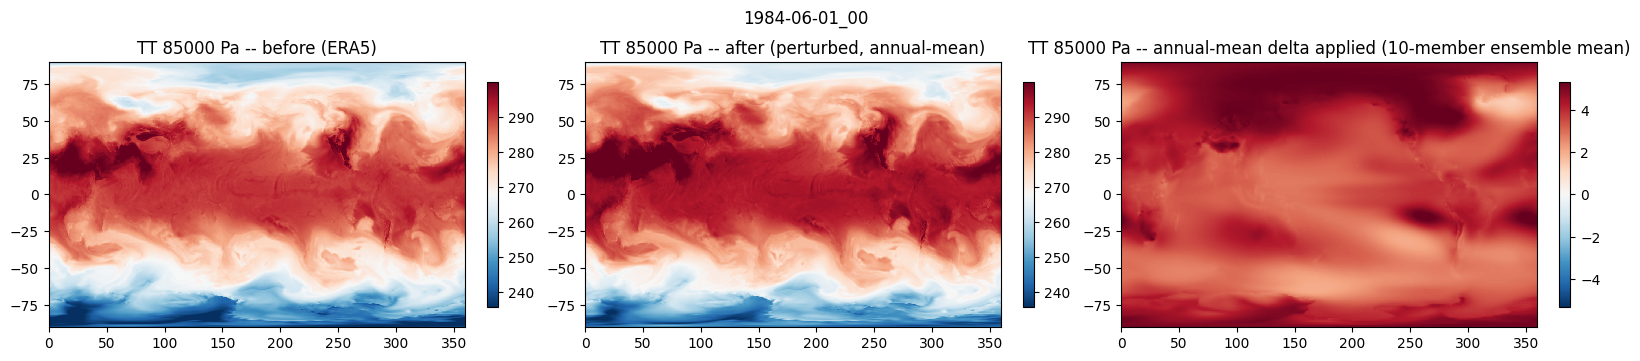

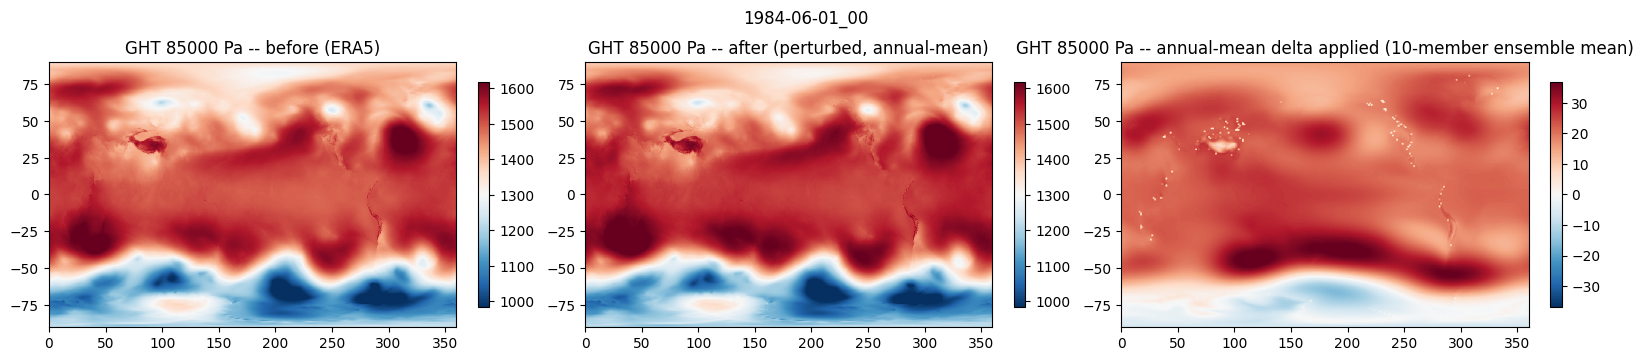

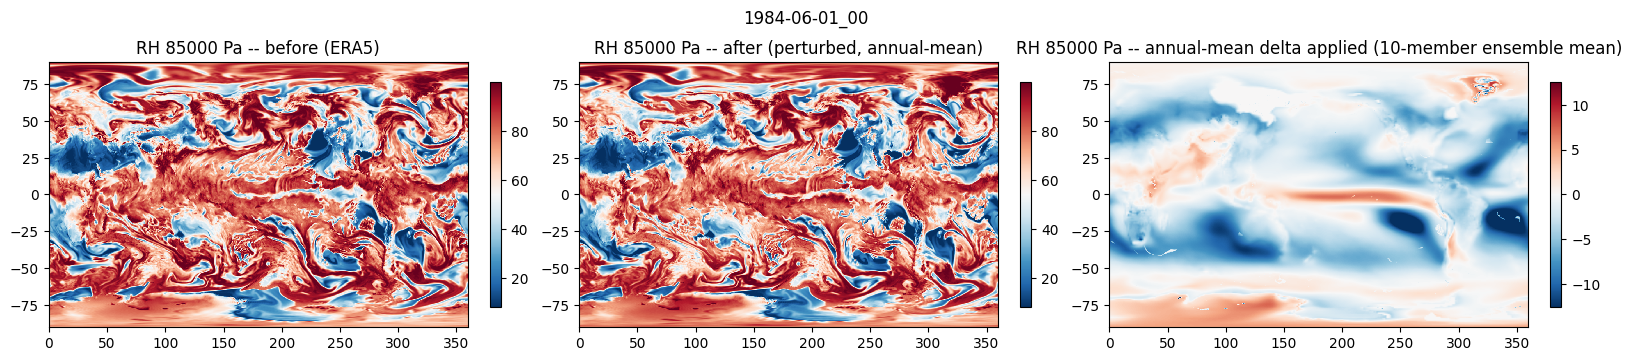

In [6]:
date0 = test_dates[0]
orig0, pert0 = results[0]["orig"], results[0]["pert"]
lat, lon = config.ERA5_LAT, config.ERA5_LON

def find(recs, field, xlvl):
    for r in recs:
        if r.field == field and abs(r.xlvl - xlvl) < 1.0:
            return r
    raise KeyError((field, xlvl))

def plot_before_after_diff(field, xlvl, cmap="RdBu_r", diff_cmap="RdBu_r"):
    ro = find(orig0, field, xlvl)
    rp = find(pert0, field, xlvl)
    d = rp.slab.astype(np.float64) - ro.slab.astype(np.float64)

    fig, axes = plt.subplots(1, 3, figsize=(16, 3.2), constrained_layout=True)
    vmin, vmax = np.nanpercentile(ro.slab, [1, 99])
    for ax, data, title in zip(axes[:2], [ro.slab, rp.slab], ["before (ERA5)", "after (perturbed, annual-mean)"]):
        im = ax.pcolormesh(lon, lat, data, vmin=vmin, vmax=vmax, cmap=cmap, shading="auto")
        ax.set_title(f"{field} {xlvl:.0f} Pa -- {title}")
        fig.colorbar(im, ax=ax, shrink=0.85)
    dmax = np.nanpercentile(np.abs(d), 99)
    im = axes[2].pcolormesh(lon, lat, d, vmin=-dmax, vmax=dmax, cmap=diff_cmap, shading="auto")
    axes[2].set_title(f"{field} {xlvl:.0f} Pa -- annual-mean delta applied (10-member ensemble mean)")
    fig.colorbar(im, ax=axes[2], shrink=0.85)
    fig.suptitle(f"{date0}", y=1.08)
    plt.show()

plot_before_after_diff("TT", 85000.0)
plot_before_after_diff("GHT", 85000.0)
plot_before_after_diff("RH", 85000.0)

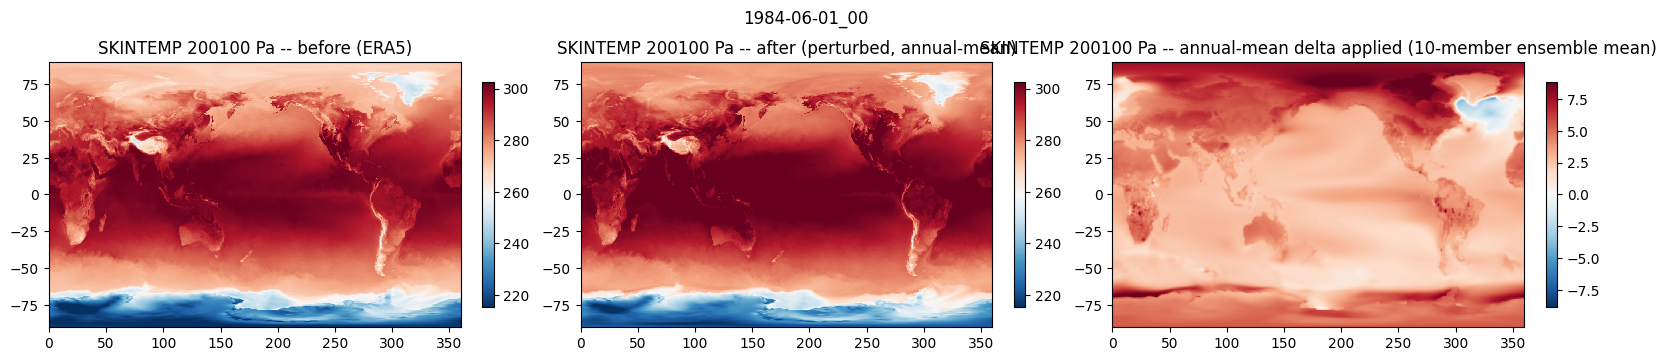

In [7]:
plot_before_after_diff("SKINTEMP", config.ERA5_SURFACE_LEVEL_PA)

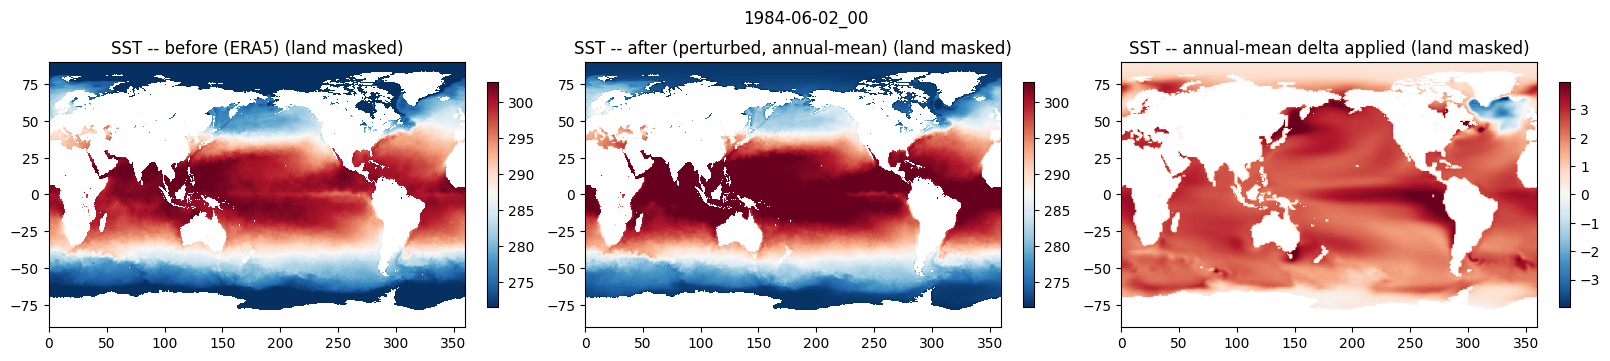

In [8]:
assert sst_dates, "no main-stream test date carries an SST record"
sst_date = sst_dates[0]
sst_idx = test_dates.index(sst_date)
orig_sst, pert_sst = results[sst_idx]["orig"], results[sst_idx]["pert"]

ro = find(orig_sst, "SST", config.ERA5_SURFACE_LEVEL_PA)
rp = find(pert_sst, "SST", config.ERA5_SURFACE_LEVEL_PA)
land = ro.slab <= SST_FILL_THRESHOLD
d = np.where(land, np.nan, rp.slab.astype(np.float64) - ro.slab.astype(np.float64))
before = np.where(land, np.nan, ro.slab)
after = np.where(land, np.nan, rp.slab)

fig, axes = plt.subplots(1, 3, figsize=(16, 3.2), constrained_layout=True)
vmin, vmax = np.nanpercentile(before, [1, 99])
for ax, data, title in zip(axes[:2], [before, after], ["before (ERA5)", "after (perturbed, annual-mean)"]):
    im = ax.pcolormesh(lon, lat, data, vmin=vmin, vmax=vmax, cmap="RdBu_r", shading="auto")
    ax.set_title(f"SST -- {title} (land masked)")
    fig.colorbar(im, ax=ax, shrink=0.85)
dmax = np.nanpercentile(np.abs(d), 99)
im = axes[2].pcolormesh(lon, lat, d, vmin=-dmax, vmax=dmax, cmap="RdBu_r", shading="auto")
axes[2].set_title("SST -- annual-mean delta applied (land masked)")
fig.colorbar(im, ax=axes[2], shrink=0.85)
fig.suptitle(f"{sst_date}", y=1.08)
plt.show()

In [9]:
# extrema / NaN check on the full stage-03 delta field, per pressure level
month0 = int(orig0[0].hdate[5:7])
for field in ["TT", "GHT", "RH"]:
    dT = deltas[month0][field]
    print(f"Variable: {field}")
    for i, lv in enumerate(deltas[month0]["lev_pa"]):
        level = dT[i]
        print(f"{lv / 100:7.0f} hPa: min={float(np.nanmin(level)):+.2f}  max={float(np.nanmax(level)):+.2f}  "
              f"mean={float(np.nanmean(level)):+.2f}  NaN={int(np.isnan(level).sum())}")
    print()


Variable: TT
      1 hPa: min=-11.25  max=-7.07  mean=-9.04  NaN=0
      2 hPa: min=-11.25  max=-7.07  mean=-9.04  NaN=0
      3 hPa: min=-11.25  max=-7.07  mean=-9.04  NaN=0
      5 hPa: min=-11.39  max=-6.52  mean=-8.62  NaN=0
      7 hPa: min=-11.56  max=-5.91  mean=-8.17  NaN=0
     10 hPa: min=-10.55  max=-4.78  mean=-7.28  NaN=0
     20 hPa: min=-8.08  max=-2.48  mean=-5.43  NaN=0
     30 hPa: min=-6.59  max=-1.26  mean=-4.26  NaN=0
     50 hPa: min=-4.26  max=+0.34  mean=-2.05  NaN=0
     70 hPa: min=-2.53  max=+1.79  mean=-0.16  NaN=0
    100 hPa: min=-1.35  max=+4.05  mean=+1.62  NaN=0
    125 hPa: min=-1.13  max=+5.48  mean=+2.04  NaN=0
    150 hPa: min=-1.27  max=+5.93  mean=+2.14  NaN=0
    175 hPa: min=-1.03  max=+6.27  mean=+2.30  NaN=0
    200 hPa: min=-0.71  max=+6.45  mean=+2.64  NaN=0
    225 hPa: min=+0.11  max=+6.62  mean=+3.18  NaN=0
    250 hPa: min=+0.88  max=+6.77  mean=+3.63  NaN=0
    300 hPa: min=+1.96  max=+6.72  mean=+4.19  NaN=0
    350 hPa: min=+2.40  max

## 3b. Multi-level delta maps -- smooth, large-scale climate-change signal check

One row per variable -- `TT` (temperature) at 850/500/200 hPa, `GHT` (geopotential
height) at 500/200 hPa, `RH` (relative humidity) at 850/500 hPa -- so all seven
delta-only maps can be scanned together, grouped by field. A PGW-consistent delta
should look like a **smooth, large-scale** pattern (e.g. broad tropical/subtropical
structure, land-sea contrast, amplification toward high latitudes or aloft) -- not
pixel-scale noise, stripes, or a corrupted field.


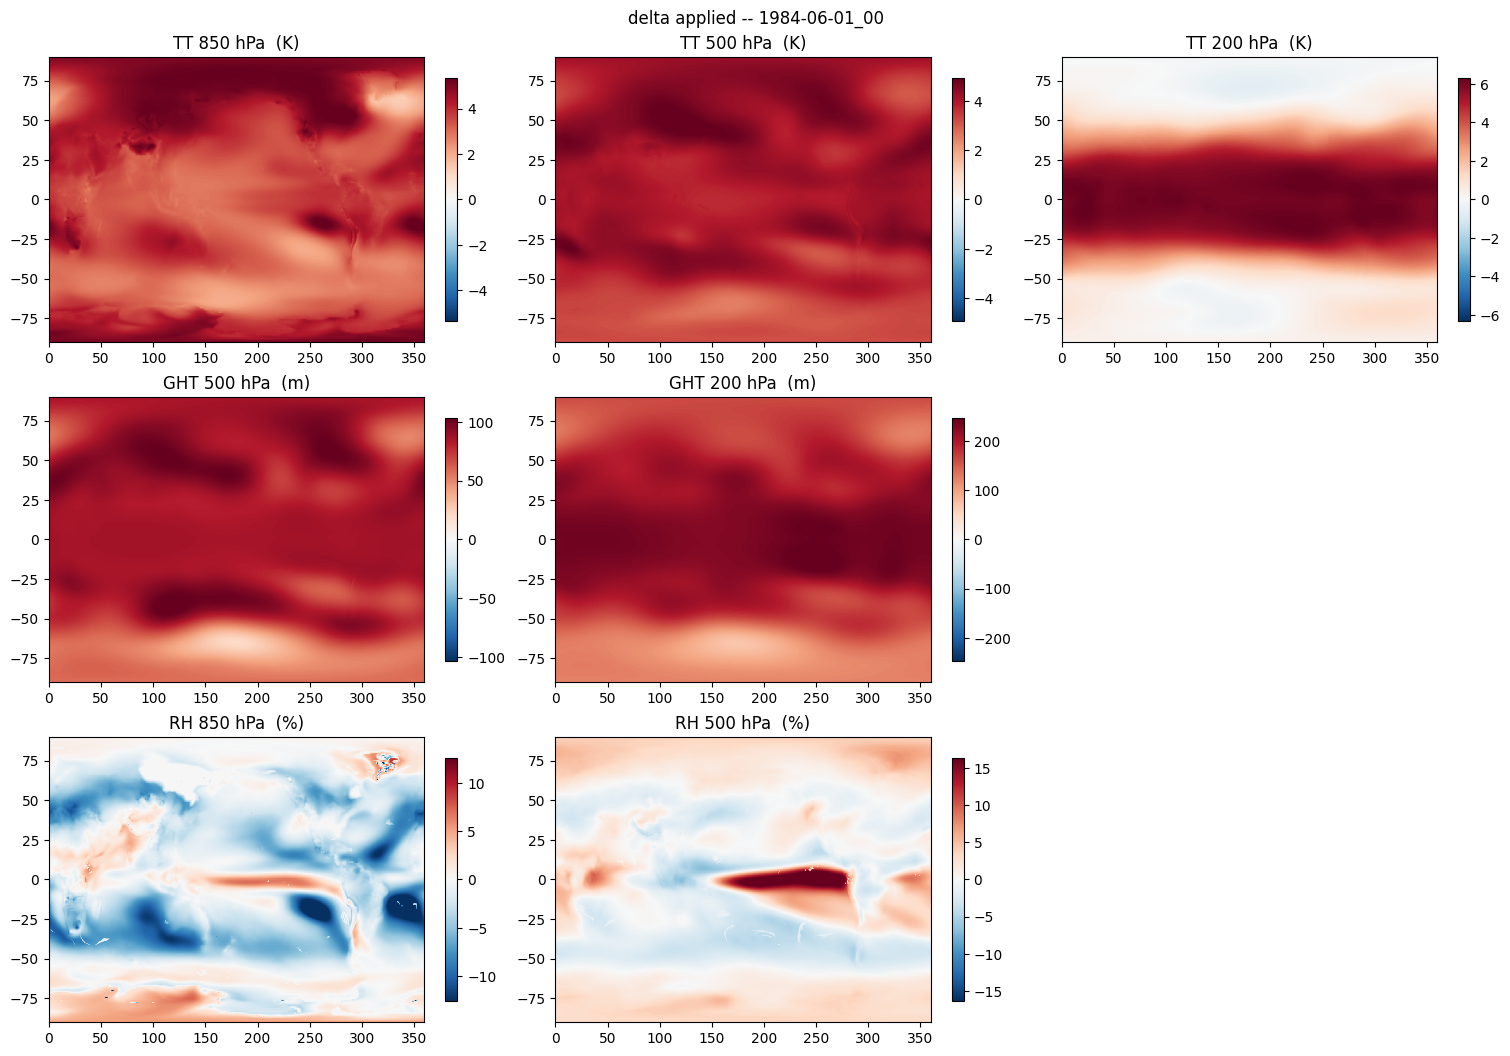

In [10]:
def plot_delta_maps(orig, pert, rows, date_label, suptitle_suffix=""):
    """rows: list of rows, each row a list of (field, xlvl_pa, unit) sharing one
    variable per row (e.g. a TT row, a GHT row, an RH row) -- deliberately omits
    before/after (see section 3 above for those) so all levels/fields can be
    scanned together for smoothness."""
    ncols = max(len(row) for row in rows)
    nrows = len(rows)
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.4 * nrows),
                              constrained_layout=True, squeeze=False)
    for row_axes, row in zip(axes, rows):
        for ax, (field, xlvl, unit) in zip(row_axes, row):
            ro = find(orig, field, xlvl)
            rp = find(pert, field, xlvl)
            d = rp.slab.astype(np.float64) - ro.slab.astype(np.float64)
            dmax = np.nanpercentile(np.abs(d), 99)
            im = ax.pcolormesh(lon, lat, d, vmin=-dmax, vmax=dmax, cmap="RdBu_r", shading="auto")
            ax.set_title(f"{field} {xlvl / 100:.0f} hPa  ({unit})")
            fig.colorbar(im, ax=ax, shrink=0.85)
        for ax in row_axes[len(row):]:
            ax.axis("off")
    fig.suptitle(f"delta applied -- {date_label}", y=1.02)
    plt.show()

delta_map_rows = [
    [("TT", 85000.0, "K"), ("TT", 50000.0, "K"), ("TT", 20000.0, "K")],
    [("GHT", 50000.0, "m"), ("GHT", 20000.0, "m")],
    [("RH", 85000.0, "%"), ("RH", 50000.0, "%")],
]
plot_delta_maps(orig0, pert0, delta_map_rows, date0, suptitle_suffix=" (annual-mean, 10-member ensemble mean)")


## 4. Vertical profile: global-mean applied delta vs. the stage-03 annual-mean delta

The reference `delta` line (red, dashed, `x` markers) is the stage-03
`ann.nc` value; `applied` (`o-`) is `perturbed - ERA5`, averaged the same
way -- the two should overlay almost exactly.

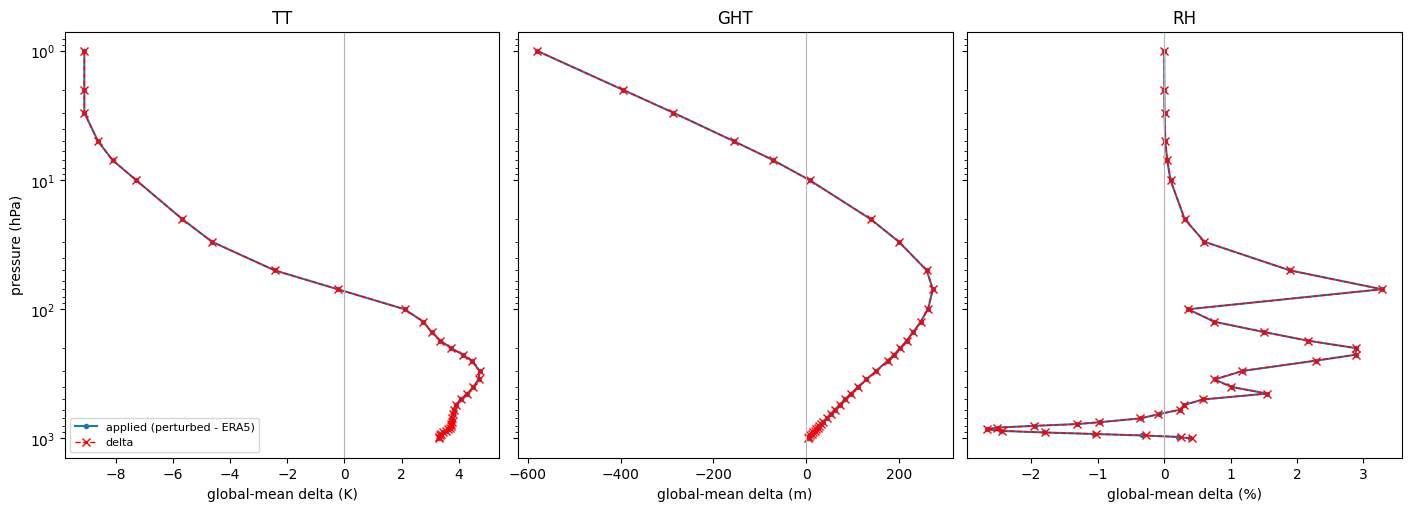

In [11]:
month0 = int(orig0[0].hdate[5:7])
lev_pa = deltas[month0]["lev_pa"]
weights = np.cos(np.deg2rad(lat))[:, None]

def applied_profile(field):
    vals = []
    for lv in lev_pa:
        ro = find(orig0, field, lv)
        rp = find(pert0, field, lv)
        d = rp.slab.astype(np.float64) - ro.slab.astype(np.float64)
        vals.append(np.average(d, weights=np.broadcast_to(weights, d.shape)))
    return np.array(vals)

def delta_profile(field, ds=None):
    d = (ds[field].values if ds is not None else deltas[month0][field]).astype(np.float64)
    return np.array([np.average(d[i], weights=np.broadcast_to(weights, d[i].shape))
                      for i in range(d.shape[0])])

fig, axes = plt.subplots(1, 3, figsize=(14, 5), sharey=True, constrained_layout=True)
for ax, field, xlabel in zip(axes, ["TT", "GHT", "RH"], ["K", "m", "%"]):
    ax.plot(applied_profile(field), lev_pa / 100, "o-", label="applied (perturbed - ERA5)", ms=3)
    ax.plot(delta_profile(field), lev_pa / 100, color="red", linestyle="--", marker="x",
            label="delta", lw=1)
    ax.axvline(0, color="0.7", lw=0.8)
    ax.set_yscale("log")
    ax.invert_yaxis()
    ax.set_xlabel(f"global-mean delta ({xlabel})")
    ax.set_title(field)
axes[0].set_ylabel("pressure (hPa)")
axes[0].legend(fontsize=8)
plt.show()

## 5. Physical sanity checks

In [12]:
for r in results:
    for rp in r["pert"]:
        if rp.field == "RH" and rp.xlvl != config.ERA5_SURFACE_LEVEL_PA:
            assert rp.slab.min() >= 0.0 and rp.slab.max() <= 100.0, \
                f"{r['date']} RH {rp.xlvl}: out of [0,100] range"
print("PASS: perturbed RH stays within [0, 100] at every level, every test date.")

d_sst = find(pert_sst, "SST", config.ERA5_SURFACE_LEVEL_PA).slab.astype(np.float64) - \
        find(orig_sst, "SST", config.ERA5_SURFACE_LEVEL_PA).slab.astype(np.float64)
ocean_mask = find(orig_sst, "SST", config.ERA5_SURFACE_LEVEL_PA).slab > SST_FILL_THRESHOLD
pert_ocean_sst = find(pert_sst, "SST", config.ERA5_SURFACE_LEVEL_PA).slab
print(f"SST delta ({sst_date}, ocean only): mean={d_sst[ocean_mask].mean():+.2f} K, "
      f"min={d_sst[ocean_mask].min():+.2f} K, max={d_sst[ocean_mask].max():+.2f} K")
assert pert_ocean_sst[ocean_mask].min() >= SST_FLOOR_K - 1e-3, "SST floor was breached"
assert 0.0 < d_sst[ocean_mask].mean() < 10.0, "SST mean delta outside a physically plausible range"
print("PASS: SST warms over ocean, respects the 271 K floor, land untouched.")

d_skt = find(pert0, "SKINTEMP", config.ERA5_SURFACE_LEVEL_PA).slab.astype(np.float64) - \
        find(orig0, "SKINTEMP", config.ERA5_SURFACE_LEVEL_PA).slab.astype(np.float64)
print(f"SKINTEMP delta: mean={d_skt.mean():+.2f} K, min={d_skt.min():+.2f} K, max={d_skt.max():+.2f} K")
assert 0.0 < d_skt.mean() < 15.0, "SKINTEMP mean delta outside a physically plausible range"

tt_profile = applied_profile("TT")
trop_mean = tt_profile[(lev_pa >= 50000) & (lev_pa <= 85000)].mean()
strat_mean = tt_profile[lev_pa <= 20000].mean()
print(f"TT delta: mid-troposphere (500-850 hPa) mean={trop_mean:+.2f} K, "
      f"lower-stratosphere (<=200 hPa) mean={strat_mean:+.2f} K")
assert trop_mean > 0, "expected tropospheric warming, got cooling"
assert strat_mean < trop_mean, "expected relative stratospheric cooling vs. tropospheric warming"
print("PASS: annual-mean delta reproduces the expected troposphere-warms /"
      " stratosphere-cools vertical structure.")

PASS: perturbed RH stays within [0, 100] at every level, every test date.
SST delta (1984-06-02_00, ocean only): mean=+1.99 K, min=-4.85 K, max=+5.63 K
PASS: SST warms over ocean, respects the 271 K floor, land untouched.
SKINTEMP delta: mean=+3.84 K, min=-4.59 K, max=+10.11 K
TT delta: mid-troposphere (500-850 hPa) mean=+3.78 K, lower-stratosphere (<=200 hPa) mean=-3.28 K
PASS: annual-mean delta reproduces the expected troposphere-warms / stratosphere-cools vertical structure.


## 6. Annual-mean != month-specific delta

The single most important thing to verify about `--annual` specifically: `ann.nc`
must not be a no-op copy of, or accidentally identical to, any one calendar
month's delta. Since the main-stream `ERA5:*` test files happen to be June dates,
the natural (and strictest available) check is against `DELTA_DIR/06.nc` -- if
`--annual` were silently broken and fell back to reusing a single month, June is
exactly the month that error would be invisible against these test files.

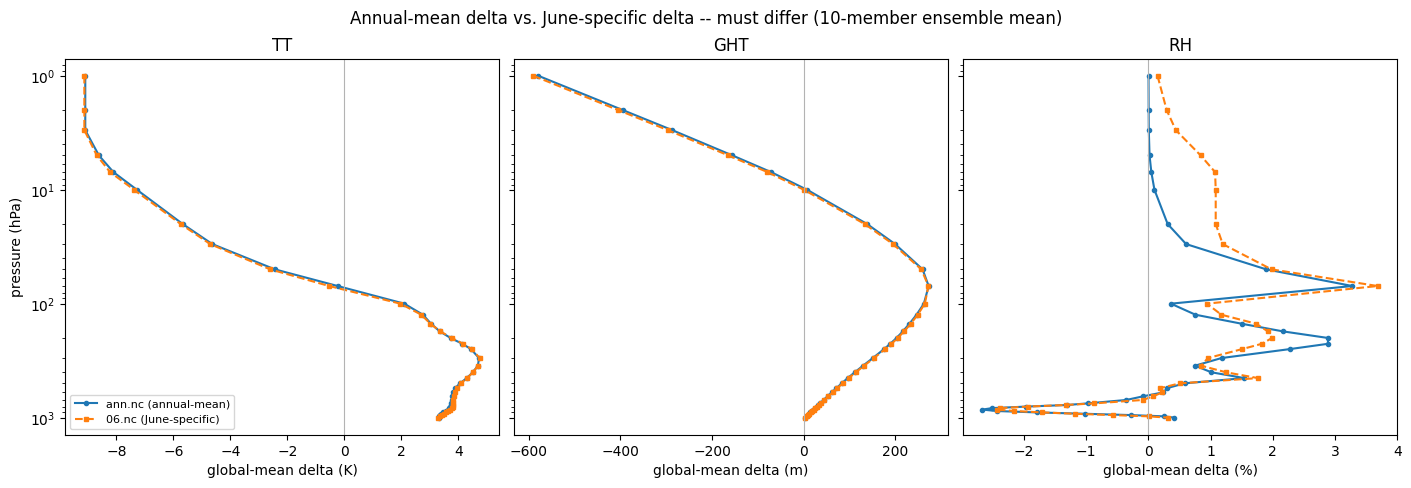

|ann.nc TT - 06.nc TT|: mean=0.565 K, max=7.825 K
PASS: the annual-mean delta is materially different from the June-specific delta,
      confirming --annual is genuinely averaging across all 12 months, not
      silently defaulting to (or coinciding with) a single month.


In [13]:
delta_06 = xr.open_dataset(config.DELTA_DIR / "06.nc")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharey=True, constrained_layout=True)
for ax, field, xlabel in zip(axes, ["TT", "GHT", "RH"], ["K", "m", "%"]):
    ann_prof = delta_profile(field, ds=ann_only)
    jun_prof = delta_profile(field, ds=delta_06)
    ax.plot(ann_prof, lev_pa / 100, "o-", label="ann.nc (annual-mean)", ms=3)
    ax.plot(jun_prof, lev_pa / 100, "s--", label="06.nc (June-specific)", ms=3)
    ax.axvline(0, color="0.7", lw=0.8)
    ax.set_yscale("log")
    ax.invert_yaxis()
    ax.set_xlabel(f"global-mean delta ({xlabel})")
    ax.set_title(field)
axes[0].set_ylabel("pressure (hPa)")
axes[0].legend(fontsize=8)
fig.suptitle("Annual-mean delta vs. June-specific delta -- must differ (10-member ensemble mean)", y=1.05)
plt.show()

diff_tt = np.abs(ann_only["TT"].values - delta_06["TT"].values)
print(f"|ann.nc TT - 06.nc TT|: mean={np.nanmean(diff_tt):.3f} K, max={np.nanmax(diff_tt):.3f} K")
assert np.nanmean(diff_tt) > 1e-3, \
    "ann.nc is suspiciously identical to 06.nc -- --annual may not be averaging correctly"
print("PASS: the annual-mean delta is materially different from the June-specific delta,")
print("      confirming --annual is genuinely averaging across all 12 months, not")
print("      silently defaulting to (or coinciding with) a single month.")

## 7. SST-update stream verification -- and cross-month consistency for free

Same checks as `05.1`'s section 6 (on-disk field-name preservation, land untouched,
applied delta matches the stage-03 delta within tolerance, floor respected). But
because this notebook auto-discovers *every* SST-update file stage 04's `--annual`
run actually produced, and that run spans several different calendar months (see
the auto-discovery cell above), this section is *also* the cross-month-consistency
check: every date -- regardless of which month it falls in -- is checked against
the exact same `ann.nc` SST delta (via `deltas[month]`, which `load_annual_delta()`
broadcasts identically to all 12 months).

In [14]:
ocean_mask_sst = apply_pgw.load_ocean_mask()
print("ocean fraction (LANDSEA-derived mask):", ocean_mask_sst.mean())

def orig_path_for_sst_update(pert_path):
    orig_name = apply_pgw._SST_UPDATE_SRC_PREFIX + pert_path.name[len(apply_pgw._SST_UPDATE_PREFIX):]
    rel_dir = pert_path.parent.relative_to(PERT_DIR)
    return ORIG_DIR / rel_dir / orig_name

def check_sst_update_file(pert_path):
    orig_path = orig_path_for_sst_update(pert_path)
    date = pert_path.name.split(":")[1]
    orig = wps.read_file(orig_path)
    pert = wps.read_file(pert_path)
    assert len(orig) == 1 and len(pert) == 1, f"{date}: expected exactly 1 record"
    ro, rp = orig[0], pert[0]
    assert ro.field == rp.field, f"{date}: field name changed by perturbation ({ro.field} -> {rp.field})"
    assert (ro.nx, ro.ny) == (config.ERA5_NX, config.ERA5_NY), f"{date}: unexpected grid size"

    land = ~ocean_mask_sst
    land_untouched = np.array_equal(ro.slab[land], rp.slab[land])
    return dict(date=date, month=date[5:7], field=ro.field, orig=ro, pert=rp,
                land_untouched=land_untouched)

sst_update_results = [check_sst_update_file(f) for f in sst_pert_files]
n_fail = sum(1 for r in sst_update_results if not r["land_untouched"])
print(f"{len(sst_update_results)} SST-update files checked, {n_fail} with land cells modified")
assert all(r["land_untouched"] for r in sst_update_results), \
    "an SST-update file's land cells were modified -- should never happen"
print("PASS: every SST-update test file's land cells (per the static LANDSEA mask) are "
      "byte-identical to the original; only ocean cells were perturbed.")

ocean fraction (LANDSEA-derived mask): 0.6611111111111111
184 SST-update files checked, 0 with land cells modified
PASS: every SST-update test file's land cells (per the static LANDSEA mask) are byte-identical to the original; only ocean cells were perturbed.


In [15]:
def cross_check_sst_update(r):
    ro, rp = r["orig"], r["pert"]
    month = int(rp.hdate[5:7])
    applied = rp.slab.astype(np.float64) - ro.slab.astype(np.float64)
    expected = deltas[month]["SST"].astype(np.float64)  # same ann.nc broadcast for every month

    not_floored = rp.slab > apply_pgw.SST_FLOOR_K
    cmp_mask = ocean_mask_sst & not_floored
    err = np.abs(applied - expected)[cmp_mask]

    floored = ocean_mask_sst & ~not_floored
    if floored.any():
        assert np.allclose(rp.slab[floored], apply_pgw.SST_FLOOR_K), \
            f"{r['date']}: SST-update floor-clamped cells not at {apply_pgw.SST_FLOOR_K} K"
    return float(err.max()) if err.size else 0.0

sst_update_errs = {r["date"]: cross_check_sst_update(r) for r in sst_update_results}

# per-month breakdown -- the whole point of this section: max per-cell error must stay
# tiny (float32 tolerance) *regardless* of which calendar month a date falls in
by_month = {}
for r in sst_update_results:
    by_month.setdefault(r["month"], []).append(sst_update_errs[r["date"]])
print("worst-case |applied - ann.nc SST delta|, by calendar month present in this run:")
for m in sorted(by_month):
    print(f"  month {m}: {len(by_month[m])} dates, worst={max(by_month[m]):.4g}")

worst_sst_update = max(sst_update_errs.values(), default=0.0)
assert worst_sst_update < 1e-2, "SST-update perturbation does not match the stage-03 annual-mean delta"
print(f"\nPASS: all {len(sst_update_errs)} SST-update test files, spanning "
      f"{len(by_month)} different calendar months ({sorted(by_month)}), match the exact same "
      f"ann.nc SST delta within float32 tolerance (worst-case {worst_sst_update:.4g}) -- direct, "
      "on-disk confirmation that --annual applies one non-seasonal delta everywhere, not a "
      "per-month one disguised as an average.")

worst-case |applied - ann.nc SST delta|, by calendar month present in this run:
  month 06: 30 dates, worst=1.526e-05
  month 07: 31 dates, worst=1.526e-05
  month 08: 31 dates, worst=1.526e-05
  month 09: 30 dates, worst=1.526e-05
  month 10: 31 dates, worst=1.526e-05
  month 11: 30 dates, worst=1.526e-05
  month 12: 1 dates, worst=1.526e-05

PASS: all 184 SST-update test files, spanning 7 different calendar months (['06', '07', '08', '09', '10', '11', '12']), match the exact same ann.nc SST delta within float32 tolerance (worst-case 1.526e-05) -- direct, on-disk confirmation that --annual applies one non-seasonal delta everywhere, not a per-month one disguised as an average.


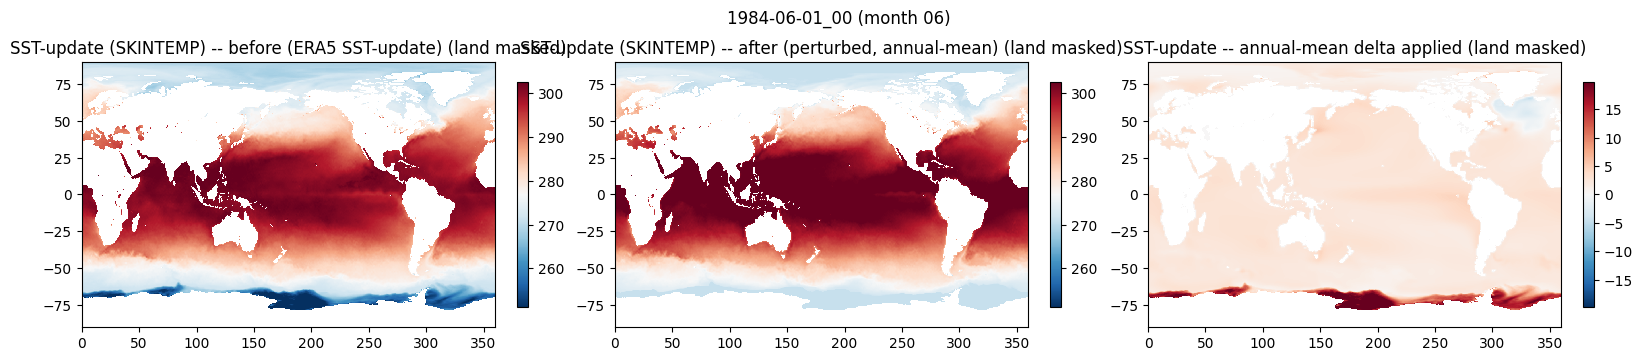

In [16]:
r0 = sst_update_results[0]
ro, rp = r0["orig"], r0["pert"]
land = ~ocean_mask_sst
before = np.where(land, np.nan, ro.slab)
after = np.where(land, np.nan, rp.slab)
d = np.where(land, np.nan, rp.slab.astype(np.float64) - ro.slab.astype(np.float64))

fig, axes = plt.subplots(1, 3, figsize=(16, 3.2), constrained_layout=True)
vmin, vmax = np.nanpercentile(before, [1, 99])
for ax, data, title in zip(axes[:2], [before, after], ["before (ERA5 SST-update)", "after (perturbed, annual-mean)"]):
    im = ax.pcolormesh(lon, lat, data, vmin=vmin, vmax=vmax, cmap="RdBu_r", shading="auto")
    ax.set_title(f"SST-update ({r0['field']}) -- {title} (land masked)")
    fig.colorbar(im, ax=ax, shrink=0.85)
dmax = np.nanpercentile(np.abs(d), 99)
im = axes[2].pcolormesh(lon, lat, d, vmin=-dmax, vmax=dmax, cmap="RdBu_r", shading="auto")
axes[2].set_title("SST-update -- annual-mean delta applied (land masked)")
fig.colorbar(im, ax=axes[2], shrink=0.85)
fig.suptitle(f"{r0['date']} (month {r0['month']})", y=1.08)
plt.show()

In [17]:
d_all = np.concatenate([
    (r["pert"].slab.astype(np.float64) - r["orig"].slab.astype(np.float64))[ocean_mask_sst]
    for r in sst_update_results
])
print(f"SST-update delta (ocean only, all {len(sst_update_results)} test dates, "
      f"{len(by_month)} calendar months): mean={d_all.mean():+.2f} K, min={d_all.min():+.2f} K, "
      f"max={d_all.max():+.2f} K")
assert 0.0 < d_all.mean() < 10.0, "SST-update mean delta outside a physically plausible range"

for r in sst_update_results:
    assert r["pert"].slab[ocean_mask_sst].min() >= apply_pgw.SST_FLOOR_K - 1e-3, \
        f"{r['date']}: SST-update floor breached"

print("PASS: SST-update stream warms over ocean, respects the 271 K floor, land untouched, "
      "consistent across all test dates and all calendar months present.")

outlier_thresh = 20.0
n_outliers = int((d_all > outlier_thresh).sum())
if n_outliers:
    print(f"\nNOTE: {n_outliers} of {d_all.size} ocean-cell/date combinations show a delta > "
          f"{outlier_thresh:.0f} K (max {d_all.max():.1f} K) -- likely isolated cases where the "
          "271 K floor corrected an already-anomalous raw ERA5 value (e.g. under permanent sea "
          "ice), not a perturbation bug.")

SST-update delta (ocean only, all 184 test dates, 7 calendar months): mean=+3.25 K, min=-4.85 K, max=+47.01 K
PASS: SST-update stream warms over ocean, respects the 271 K floor, land untouched, consistent across all test dates and all calendar months present.

NOTE: 1973538 of 126296128 ocean-cell/date combinations show a delta > 20 K (max 47.0 K) -- likely isolated cases where the 271 K floor corrected an already-anomalous raw ERA5 value (e.g. under permanent sea ice), not a perturbation bug.


## Summary

- **Structural integrity**: every auto-discovered test file touches exactly the
  expected records and nothing else -- identical behavior to `05.1`'s
  month-specific run, since `perturb_field`'s logic is shared code, only the delta
  values it looks up differ.
- **Quantitative correctness**: `perturbed - original` matches the stage-03
  **annual-mean** delta file (`03_delta/ann.nc`) within float32 tolerance at every
  level, for every test date -- including `SST` (ocean-only, floor-respecting).
- **Physical plausibility**: the applied delta reproduces the textbook PGW pattern
  -- tropospheric warming with geopotential expansion, stratospheric cooling,
  ocean and land surface warming -- driven by the 10-member ensemble-mean signal.
- **Annual != month-specific**: `ann.nc` differs materially from `06.nc` (the
  June-specific delta) -- confirming `--annual` is a genuine 12-month average, not
  an accidental pass-through of one month.
- **Cross-month consistency**: the auto-discovered SST-update stream spans several
  different calendar months in this run, and *every* date -- regardless of its own
  month -- matches the exact same `ann.nc` SST delta within float32 tolerance --
  direct, on-disk evidence that `--annual` applies one non-seasonal delta
  uniformly, not a per-month one disguised as an average.

This notebook auto-discovers its test set from `config.PERTURBED_IM_DIR_ANNUAL`,
so re-running it after `04_apply_perturbation.py --annual` processes more
years/months verifies the new output without any edits here.

The `--annual` (climate-mean) mode of the 10-member-ensemble-mean LENS2 -> ERA5
PGW pipeline is verified correct: structurally sound, quantitatively exact against
its own stage-03 output, physically plausible, genuinely non-seasonal, and applied
consistently regardless of a file's own calendar month.